In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import f


# ------------ Lecture des fichiers CSV -----
df_industries = pd.read_csv("C:/Users/patri/Desktop/ECAP/M1/cours/actif_financier/projet_actifs_financiers/source/Portefeuilles_Industries_49.csv")
df_FamaFrench  = pd.read_csv("C:/Users/patri/Desktop/ECAP/M1/cours/actif_financier/projet_actifs_financiers/source/FamaFrench_5F.csv")
# ----------- Conversion des colonnes de date -----
# Conversion de la colonne 'Unnamed: 0' en objet datetime (format AAAAMM)
df_industries['Date'] = pd.to_datetime(df_industries['Unnamed: 0'].astype(str), format='%Y%m')
df_FamaFrench['Date'] = pd.to_datetime(df_FamaFrench['Unnamed: 0'].astype(str), format='%Y%m')

# ----------- Définir la date comme index -----
# Cela permet d’accéder aux lignes par date et facilite les opérations temporelles
df_industries.set_index('Date', inplace=True)
df_FamaFrench.set_index('Date', inplace=True)

# ----------- Suppression des colonnes inutiles -----
# La colonne 'Unnamed: 0' n'est plus nécessaire après avoir mis Date comme index
df_industries.drop(columns=['Unnamed: 0'], inplace=True)
df_FamaFrench.drop(columns=['Unnamed: 0'], inplace=True)

In [3]:

# jointure des 2 dataframes :  df_industries et df_FamaFrench , on gardera uniquement les index qu'ils ont en commun

jointure = pd.merge(
    df_industries,
    df_FamaFrench,
    left_index=True,
    right_index=True,
    how="inner"
)

jointure_reduit = jointure[["Books", "Meals", "Mkt-RF", "SMB", "HML", "RMW","CMA","RF"]] # on reduit le nombre de colonnes de la jointure , en prenant uniquement nos 2 colonnes de mes industries: "Books" et "Meals" et toutes les 6 colonnes du df FamaFrench

df_actions = jointure_reduit[["Books", "Meals"]] # le df composé de mes 2 industries 
actions_nom = df_actions.columns
PR = df_actions.subtract(jointure_reduit["RF"], axis=0) # calcul de la prime de risque des actifs en soustrayant toutes les obs du dataframe à chaque element de Rf

PRM = jointure["Mkt-RF"].values # la prime de risque du marché pour le CAPM
FF3 = jointure[["Mkt-RF", "SMB", "HML"]].values # les 3 facteurs pour le FF3
FF5 = jointure[["Mkt-RF", "SMB", "HML", "RMW","CMA"]].values # les 5 facteurs pour le FF3


Le CAPM : MCO à un seul facteur: le marché

In [5]:
# CREATION DE LISTES 
betas = []
alphas = []
t_stats_alpha = []
t_stats_beta=[]
r_squared = []
adj_r_squared = [] # Nouvelle liste

## transformation matricielle de X et Y

for action_i in actions_nom:
    Y = PR[action_i].values # Y contiendra toutes les observations (valeurs) de la colonne sélectionnée, sans les étiquettes d'index ou de colonne 
    X = np.column_stack((np.ones(len(Y)), PRM))  # ajout de la constante (matrice X)
    
    #estimateurs
    theta_i = np.linalg.inv(X.T @ X) @ X.T @ Y 
    alpha_i, beta_i = theta_i
    alphas.append(alpha_i)
    betas.append(beta_i)

    #calcul des statistiques
    eps_i = Y - X @ theta_i
    residuals = Y - X@theta_i
    sig2_eps_i = np.sum(residuals**2) / (len(Y) - X.shape[1]) 
    cov_theta_i = sig2_eps_i * np.linalg.inv(X.T @ X)  

    se_theta_i = np.sqrt(np.diag(cov_theta_i))
    t_alpha_i, t_beta_i = theta_i / se_theta_i
    t_stats_alpha.append(t_alpha_i)
    t_stats_beta.append(t_beta_i)  


# Mise enplace d'un dataframe pour stocker les resultats stats
capm_annual = pd.DataFrame({
    "Alpha": np.array(alphas) * 252,
    "Beta": betas,
    "t_alpha": [f"{t:.2f}*" if abs(t) > 1.96 else f"{t:.2f}" for t in t_stats_alpha],
    "t_beta": [f"{t:.2f}*" if abs(t) > 1.96 else f"{t:.2f}" for t in t_stats_beta],
    "E[ri]-E[rf]": PR.mean()*252  
}, index=actions_nom)

# Calcul des p-values
p_alpha = [2 * (1 - stats.t.cdf(abs(t), df=len(PR)-2)) for t in t_stats_alpha]
p_beta  = [2 * (1 - stats.t.cdf(abs(t), df=len(PR)-2)) for t in t_stats_beta]

# Formatage avec étoiles
p_alpha_fmt = [f"{p:.6f}*" if p < 0.05 else f"{p:.6f}" for p in p_alpha]
p_beta_fmt  = [f"{p:.6f}*" if p < 0.05 else f"{p:.6f}" for p in p_beta]

# Ajout au DataFrame
capm_annual['p_alpha'] = p_alpha_fmt
capm_annual['p_beta']  = p_beta_fmt

# Calcul du R² pour chaque action / portefeuille

for action_i in actions_nom:
    Y = PR[action_i].values
    X = np.column_stack((np.ones(len(Y)), PRM))
    
    # estimateurs
    theta_i = np.linalg.inv(X.T @ X) @ X.T @ Y
    Y_hat = X @ theta_i  # valeurs prédites
    ss_total = np.sum((Y - np.mean(Y))**2)  # variance totale
    ss_res = np.sum((Y - Y_hat)**2)          # variance non expliquée
    r2 = 1 - ss_res / ss_total
    r_squared.append(r2)

# Ajouter au DataFrame
capm_annual['R2'] = r_squared

# Calcul du R² ajusté pour chaque action / portefeuille
for action_i in actions_nom:
    Y = PR[action_i].values
    X = np.column_stack((np.ones(len(Y)), PRM))
    
    # Estimateurs
    theta_i = np.linalg.inv(X.T @ X) @ X.T @ Y
    Y_hat = X @ theta_i
    
    # Calcul des sommes des carrés
    ss_total = np.sum((Y - np.mean(Y))**2)
    ss_res = np.sum((Y - Y_hat)**2)
    
    # R-squared classique
    r2 = 1 - ss_res / ss_total
    r_squared.append(r2)
    
    # R-squared ajusté
    n = len(Y)
    p = 1 # On a seulement le marché comme prédicteur
    r2_adj = 1 - (1 - r2) * (n - 1) / (n - p - 1)
    adj_r_squared.append(r2_adj)

# Ajouter au DataFrame
capm_annual['R2_ajusté'] = adj_r_squared

# Affichage 
print(capm_annual.sort_values("Alpha", ascending=True).head(10))



           Alpha      Beta t_alpha  t_beta  E[ri]-E[rf]   p_alpha     p_beta  \
Books -32.202822  1.093965   -0.99  38.16*   132.242727  0.322333  0.000000*   
Meals  47.052613  1.040556    1.30  32.59*   203.469786  0.194255  0.000000*   

             R2  R2_ajusté  
Books  0.661283   0.660829  
Meals  0.587469   0.586916  


PARTIE 2

Fama French à 3 Facteurs (FF3)

In [12]:
# --- 1. PRÉPARATION DES FACTEURS ET DES LISTES ---
# On récupère les 3 facteurs du modèle Fama-French
PRM = jointure_reduit["Mkt-RF"].values
SMB = jointure_reduit["SMB"].values
HML = jointure_reduit["HML"].values

# On crée des tableaux numpy vides pour stocker les resultats
alphas, betas_mkt, betas_smb, betas_hml = [], [], [], []
t_stats_alpha, t_stats_mkt, t_stats_smb, t_stats_hml = [], [], [], []
r_squared = []
adj_r_squared = [] 

# Chiffres a connaitre
n_obs = len(PR)  # le nombre d'obs
k_facteurs = 3 # Mkt-RF, SMB, HML
df = n_obs - (k_facteurs + 1) # Degrés de liberté (N - K - 1)

# ------ BOUCLE DE RÉGRESSION PAR ACTION ---
for action_i in actions_nom:
    Y = PR[action_i].values
    X = np.column_stack((np.ones(n_obs), PRM, SMB, HML))   # Matrice X : Constante (1), Marché, SMB, HML
    
    # Estimateurs MCO : (X'X)^-1 X'Y
    theta_i = np.linalg.inv(X.T @ X) @ X.T @ Y 
    alpha_i, b_mkt, b_smb, b_hml = theta_i
    
    alphas.append(alpha_i)
    betas_mkt.append(b_mkt)
    betas_smb.append(b_smb)
    betas_hml.append(b_hml)

    # Calcul stats
    residuals = Y - X @ theta_i
    sig2_eps_i = np.sum(residuals**2) / df
    cov_theta_i = sig2_eps_i * np.linalg.inv(X.T @ X)
    se_theta_i = np.sqrt(np.diag(cov_theta_i))
    t_vals = theta_i / se_theta_i

    # ajout dans les tableaux numpy vides 
    t_stats_alpha.append(t_vals[0])
    t_stats_mkt.append(t_vals[1])
    t_stats_smb.append(t_vals[2])
    t_stats_hml.append(t_vals[3])

    # Calcul du R²
    ss_total = np.sum((Y - np.mean(Y))**2)
    ss_res = np.sum(residuals**2)
    r_squared.append(1 - ss_res / ss_total)

    # Calcul du R² ajusté
    ss_total = np.sum((Y - np.mean(Y))**2)
    ss_res = np.sum(residuals**2)
    r2_adj = 1 - (ss_res / df) / (ss_total / (n_obs - 1))
    adj_r_squared.append(r2_adj)


# ------CALCUL DES P-VALUES ---
p_alpha = [2 * (1 - stats.t.cdf(abs(t), df)) for t in t_stats_alpha]
p_mkt   = [2 * (1 - stats.t.cdf(abs(t), df)) for t in t_stats_mkt]
p_smb   = [2 * (1 - stats.t.cdf(abs(t), df)) for t in t_stats_smb]
p_hml   = [2 * (1 - stats.t.cdf(abs(t), df)) for t in t_stats_hml]


# ------ CRÉATION DU DATAFRAME FINAL ---
fama_french_annual = pd.DataFrame({
    "Alpha (Année)": np.array(alphas) * 252,
    "Beta_Mkt": betas_mkt,
    "Beta_SMB": betas_smb,
    "Beta_HML": betas_hml,
    
    "t_alpha": [f"{t:.2f}*" if abs(t) > 1.96 else f"{t:.2f}" for t in t_stats_alpha],
    "t_Mkt": [f"{t:.2f}*" if abs(t) > 1.96 else f"{t:.2f}" for t in t_stats_mkt],
    "t_SMB": [f"{t:.2f}*" if abs(t) > 1.96 else f"{t:.2f}" for t in t_stats_smb],
    "t_HML": [f"{t:.2f}*" if abs(t) > 1.96 else f"{t:.2f}" for t in t_stats_hml],

    "p_alpha": [f"{p:.6f}*" if p < 0.05 else f"{p:.6f}" for p in p_alpha],
    "p_Mkt":   [f"{p:.6f}*" if p < 0.05 else f"{p:.6f}" for p in p_mkt],
    "p_SMB":   [f"{p:.6f}*" if p < 0.05 else f"{p:.6f}" for p in p_smb],
    "p_HML":   [f"{p:.6f}*" if p < 0.05 else f"{p:.6f}" for p in p_hml],


    "R2": r_squared,
    "R2 ajusté": adj_r_squared,
    "E[ri]-E[rf]": PR.mean() * 252
}, index=actions_nom)

# Affichage du Top 10 par Alpha
print(fama_french_annual.sort_values("Alpha (Année)", ascending=False).head(10))

       Alpha (Année)  Beta_Mkt  Beta_SMB  Beta_HML t_alpha   t_Mkt  t_SMB  \
Meals      36.586711  1.004039  0.246075  0.069572    1.02  30.04*  5.11*   
Books     -58.716245  1.075088  0.277116  0.240238   -1.89  37.03*  6.62*   

       t_HML   p_alpha      p_Mkt      p_SMB      p_HML        R2  R2 ajusté  \
Meals   1.44  0.307670  0.000000*  0.000000*   0.149936  0.603133   0.601533   
Books  5.73*  0.059647  0.000000*  0.000000*  0.000000*  0.695117   0.693887   

       E[ri]-E[rf]  
Meals   203.469786  
Books   132.242727  


Rolling window pour le FF3

In [13]:
Rt= PR.values   
T = FF3.shape[0]
nb_pf = Rt.shape[1]
print("Le nombre de portefeuilles est de:",nb_pf)
print("Le nombre de périodes considérées:",T)

# ----- Paramètres de la rolling window -----
RW = 360  # Taille du Rolling window : 360 observations (ex. 30 ans de données mensuelles)
nb_beta = FF3.shape[1] + 1  # Nombre de coefficients à estimer : nb de facteurs + constante (alpha)


resultats = np.zeros((T - RW, nb_beta, nb_pf))    # Initialisation du tableau de résultats

# Debut de la Boucle sur chaque fenêtre temporelle
for j in range(T - RW):
    X = np.column_stack((np.ones(RW), FF3[j:RW+j, :]))
    for p in range(nb_pf):   # Boucle sur chaque portefeuille
        Y = Rt[j:(RW+j), p]
      
        resultats[j, :, p] = np.linalg.inv(X.T @ X) @ (X.T @ Y)  # Calcul des coefficients par moindres carrés



Le nombre de portefeuilles est de: 2
Le nombre de périodes considérées: 748


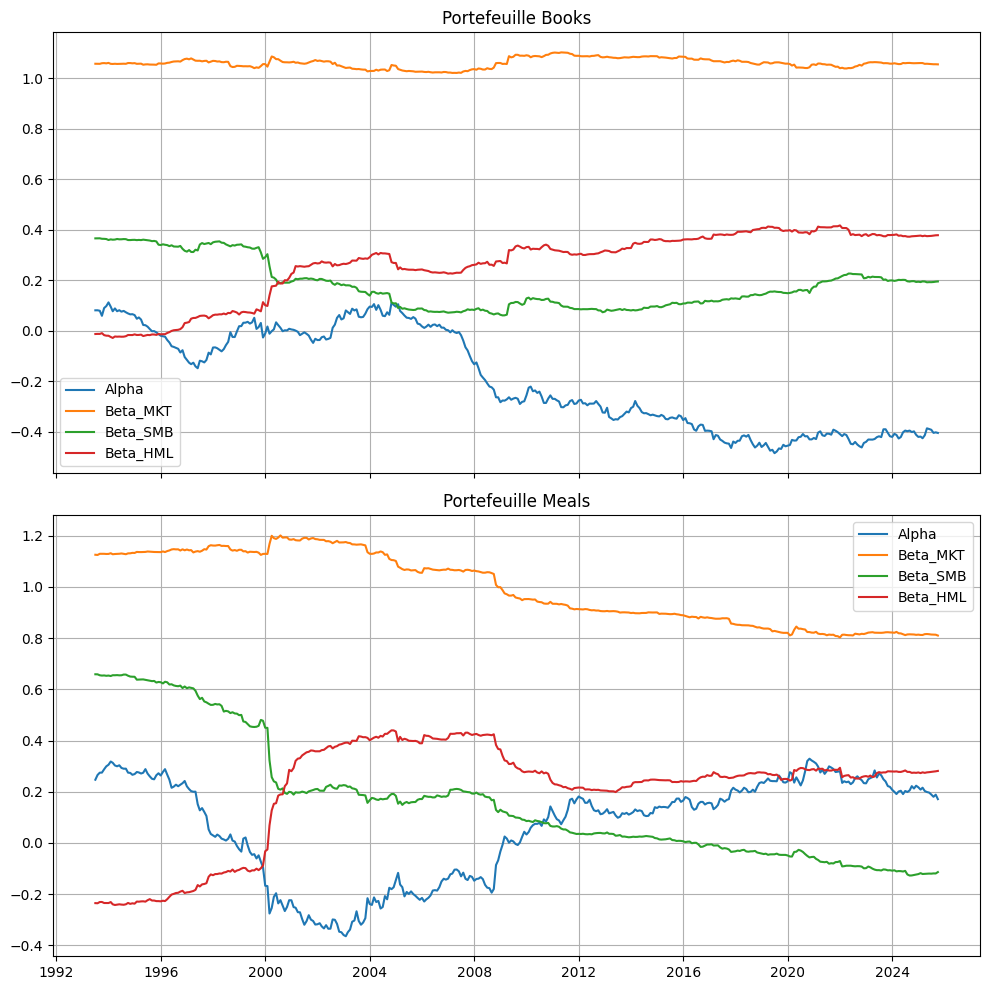

In [8]:
# ----------- Création de la figure et des axes -----

fig, axes = plt.subplots(2, 1, figsize=(10, 10), sharex=True)
axes = axes.flatten()
dates = df_actions.index[RW:]
for p in range(nb_pf):            #  pour chaque portefeuille
    ax = axes[p]
    labels_beta=["Alpha", "Beta_MKT", "Beta_SMB", "Beta_HML"]
    for b in range(nb_beta):      # pour chaque coefficient estimé
        ax.plot(dates,resultats[:, b, p], label=labels_beta[b])

    ax.set_title(f"Portefeuille {df_actions.columns[p]}")
    ax.grid(True)
    ax.legend()

plt.tight_layout()
plt.show()

PARTIE 3

Fama French à 5 Facteurs 

In [11]:
# --- 1. PRÉPARATION DES FACTEURS ET DES LISTES ---
# On récupère les 5 facteurs du modèle Fama-French
PRM = jointure_reduit["Mkt-RF"].values
SMB = jointure_reduit["SMB"].values
HML = jointure_reduit["HML"].values
RMW = jointure_reduit["RMW"].values
CMA = jointure_reduit["CMA"].values

# On crée des tableaux numpy vides pour stocker les résultats
alphas = []
betas_mkt, betas_smb, betas_hml, betas_rmw, betas_cma = [], [], [], [], []

t_stats_alpha = []
t_stats_mkt, t_stats_smb, t_stats_hml, t_stats_rmw, t_stats_cma = [], [], [], [], []

r_squared = []
adj_r_squared = []

# Chiffres à connaître
n_obs = len(PR)          # nombre d'observations
k_facteurs = 5           # Mkt-RF, SMB, HML, RMW, CMA
df = n_obs - (k_facteurs + 1)   # degrés de liberté (N - K - 1)

# ------ BOUCLE DE RÉGRESSION PAR ACTION ---
for action_i in actions_nom:
    Y = PR[action_i].values
    X = np.column_stack((np.ones(n_obs), PRM, SMB, HML, RMW, CMA))  # Matrice X : Constante + 5 facteurs
    
    # Estimateurs MCO : (X'X)^-1 X'Y
    theta_i = np.linalg.inv(X.T @ X) @ X.T @ Y
    alpha_i, b_mkt, b_smb, b_hml, b_rmw, b_cma = theta_i

    # Stockage
    alphas.append(alpha_i)
    betas_mkt.append(b_mkt)
    betas_smb.append(b_smb)
    betas_hml.append(b_hml)
    betas_rmw.append(b_rmw)
    betas_cma.append(b_cma)

    # Calcul des statistiques
    residuals = Y - X @ theta_i
    sig2_eps_i = np.sum(residuals**2) / df
    cov_theta_i = sig2_eps_i * np.linalg.inv(X.T @ X)
    se_theta_i = np.sqrt(np.diag(cov_theta_i))
    t_vals = theta_i / se_theta_i

    t_stats_alpha.append(t_vals[0])
    t_stats_mkt.append(t_vals[1])
    t_stats_smb.append(t_vals[2])
    t_stats_hml.append(t_vals[3])
    t_stats_rmw.append(t_vals[4])
    t_stats_cma.append(t_vals[5])

    # Calcul du R²
    ss_total = np.sum((Y - np.mean(Y))**2)
    ss_res = np.sum(residuals**2)
    r2 = 1 - ss_res / ss_total
    r_squared.append(r2)

    # Calcul du R² ajusté (formule cohérente avec ton code)
    r2_adj = 1 - (ss_res / df) / (ss_total / (n_obs - 1))
    adj_r_squared.append(r2_adj)


# ------ CALCUL DES P-VALUES ---
p_alpha = [2 * (1 - stats.t.cdf(abs(t), df)) for t in t_stats_alpha]
p_mkt   = [2 * (1 - stats.t.cdf(abs(t), df)) for t in t_stats_mkt]
p_smb   = [2 * (1 - stats.t.cdf(abs(t), df)) for t in t_stats_smb]
p_hml   = [2 * (1 - stats.t.cdf(abs(t), df)) for t in t_stats_hml]
p_rmw   = [2 * (1 - stats.t.cdf(abs(t), df)) for t in t_stats_rmw]
p_cma   = [2 * (1 - stats.t.cdf(abs(t), df)) for t in t_stats_cma]


# ------ CRÉATION DU DATAFRAME FINAL ---
fama_french_annual = pd.DataFrame({
    "Alpha (Année)": np.array(alphas) * 252,

    "Beta_Mkt": betas_mkt,
    "Beta_SMB": betas_smb,
    "Beta_HML": betas_hml,
    "Beta_RMW": betas_rmw,
    "Beta_CMA": betas_cma,

    "t_alpha": [f"{t:.2f}*" if abs(t) > 1.96 else f"{t:.2f}" for t in t_stats_alpha],
    "t_Mkt":   [f"{t:.2f}*" if abs(t) > 1.96 else f"{t:.2f}" for t in t_stats_mkt],
    "t_SMB":   [f"{t:.2f}*" if abs(t) > 1.96 else f"{t:.2f}" for t in t_stats_smb],
    "t_HML":   [f"{t:.2f}*" if abs(t) > 1.96 else f"{t:.2f}" for t in t_stats_hml],
    "t_RMW":   [f"{t:.2f}*" if abs(t) > 1.96 else f"{t:.2f}" for t in t_stats_rmw],
    "t_CMA":   [f"{t:.2f}*" if abs(t) > 1.96 else f"{t:.2f}" for t in t_stats_cma],

    "p_alpha": [f"{p:.6f}*" if p < 0.05 else f"{p:.6f}" for p in p_alpha],
    "p_Mkt":   [f"{p:.6f}*" if p < 0.05 else f"{p:.6f}" for p in p_mkt],
    "p_SMB":   [f"{p:.6f}*" if p < 0.05 else f"{p:.6f}" for p in p_smb],
    "p_HML":   [f"{p:.6f}*" if p < 0.05 else f"{p:.6f}" for p in p_hml],
    "p_RMW":   [f"{p:.6f}*" if p < 0.05 else f"{p:.6f}" for p in p_rmw],
    "p_CMA":   [f"{p:.6f}*" if p < 0.05 else f"{p:.6f}" for p in p_cma],

    "R2": r_squared,
    "R2 ajusté": adj_r_squared,

    "E[ri]-E[rf]": PR.mean() * 252
}, index=actions_nom)

# Affichage du Top 10 par Alpha
print(fama_french_annual.sort_values("Alpha (Année)", ascending=False).head(10))

       Alpha (Année)  Beta_Mkt  Beta_SMB  Beta_HML  Beta_RMW  Beta_CMA  \
Meals     -26.324252  1.042246  0.427259  0.001007  0.765153  0.057384   
Books     -88.415302  1.087511  0.371262  0.239096  0.404487 -0.048715   

      t_alpha   t_Mkt  t_SMB  t_HML  ...  t_CMA    p_alpha      p_Mkt  \
Meals   -0.79  32.59*  9.19*   0.02  ...   0.64   0.431002  0.000000*   
Books  -2.87*  36.92*  8.67*  4.33*  ...  -0.59  0.004188*  0.000000*   

           p_SMB      p_HML      p_RMW     p_CMA        R2  R2 ajusté  \
Meals  0.000000*   0.986594  0.000000*  0.522891  0.670528   0.668308   
Books  0.000000*  0.000017*  0.000000*  0.556025  0.715229   0.713310   

       E[ri]-E[rf]  
Meals   203.469786  
Books   132.242727  

[2 rows x 21 columns]


Rolling window

In [10]:
Rt= PR.values

T = FF5.shape[0]
nb_pf = Rt.shape[1]
print("Le nombre de portefeuilles est de:",nb_pf)
print("Le nombre de périodes considérées:",T)


RW=360
nb_beta=FF5.shape[1]+1 #(nb de facteurs + constante)
resultats=resultats = np.zeros((T - RW, nb_beta, nb_pf)) # dim 0 (lignes): nb de regressions, dim 1 (colonnes): nb de coefficients estimés, dim 2: nb de portefeuilles
for j in range(T-RW):
    X=np.column_stack((np.ones(RW),FF5[j:RW+j,:]))
    for p in range(nb_pf):
        #print((p,j))
        Y=Rt[j:(RW+j),p]
        resultats[j,:,p]=np.linalg.inv(X.T@X)@(X.T@Y)

Le nombre de portefeuilles est de: 2
Le nombre de périodes considérées: 748


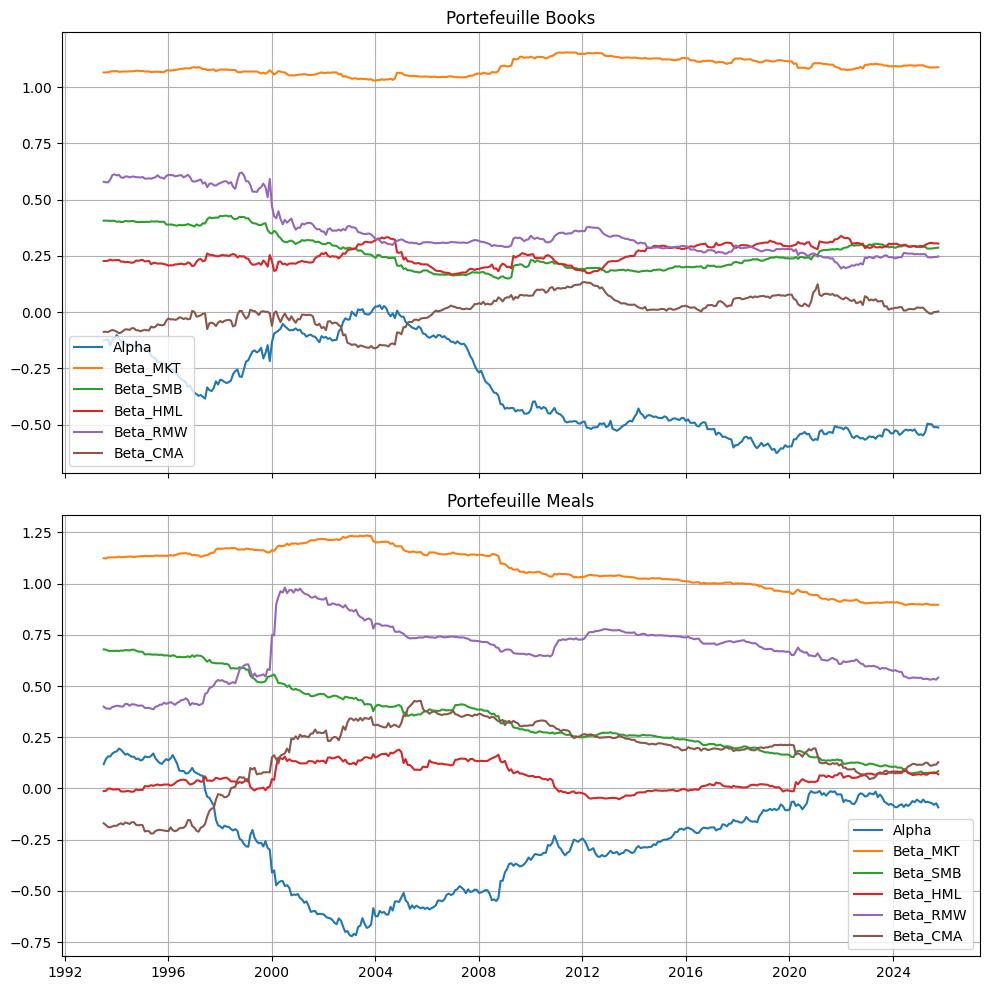

In [11]:
# -----------Création de la figure et des axes -----

fig, axes = plt.subplots(2, 1, figsize=(10, 10), sharex=True)
axes = axes.flatten()
dates = df_actions.index[RW:]
for p in range(nb_pf):            # pour chaque portefeuille
    ax = axes[p]
    labels_beta=["Alpha", "Beta_MKT", "Beta_SMB", "Beta_HML", "Beta_RMW", "Beta_CMA"]
    for b in range(nb_beta):      # pour chaque coefficient estimé
        ax.plot(dates,resultats[:, b, p], label=labels_beta[b])

    ax.set_title(f"Portefeuille {df_actions.columns[p]}")
    ax.grid(True)
    ax.legend()

plt.tight_layout()
plt.show()

Le test de CHOW , pour le FF3 et FF4

In [14]:
# 1. Fonction d'estimation (SSR par portefeuille)
def ols_theta_ssr(Y, X):
    if Y.ndim == 1:
        Y = Y.reshape(-1, 1)
    
    # Ajout automatique de la constante (Alpha)
    Xc = np.column_stack((np.ones(X.shape[0]), X))  
    
    # Résolution matricielle : (X'X)^-1 X'Y
    theta = np.linalg.inv(Xc.T @ Xc) @ (Xc.T @ Y)   
    
    # Calcul des résidus pour obtenir le SSR
    eps = Y - Xc @ theta
    SSR_pf = np.sum(eps**2, axis=0) # SSR pour chaque colonne (chaque action)
    
    return theta, SSR_pf

# 2. Fonction du Test de Chow
def execute_chow_complet(Y_data, X_facteurs, split_point):
    T, n_pf = Y_data.shape
    k = X_facteurs.shape[1] + 1  # Nombre de facteurs + 1 pour l'Alpha
    
    # --- Modèle sur toute la période ---
    theta_c, SSR_c = ols_theta_ssr(Y_data, X_facteurs)
    
    # --- Modèle période 1 (Avant split) ---
    Y1, X1 = Y_data[:split_point, :], X_facteurs[:split_point, :]
    theta_1, SSR_1 = ols_theta_ssr(Y1, X1)
    
    # --- Modèle période 2 (Après split) ---
    Y2, X2 = Y_data[split_point:, :], X_facteurs[split_point:, :]
    theta_2, SSR_2 = ols_theta_ssr(Y2, X2)
    
    T1, T2 = len(Y1), len(Y2)
    
    # Calcul des stats par portefeuille
    F_stats = []
    p_vals = []
    
    for p in range(n_pf):
        # La formule de Chow
        num = (SSR_c[p] - (SSR_1[p] + SSR_2[p])) / k
        den = (SSR_1[p] + SSR_2[p]) / (T1 + T2 - 2*k)
        f_stat = num / den
        
        p_val = 1 - f.cdf(f_stat, k, T1 + T2 - 2*k)
        
        F_stats.append(f_stat)
        p_vals.append(p_val)
        
    return pd.DataFrame({
        "F_stat": F_stats, 
        "p_value": p_vals,
        "Significatif": [p < 0.05 for p in p_vals]
    }, index=PR.columns)

# --- 3. LANCEMENT DES TESTS ---

# On définit le point de rupture (ex: à l'indice 440)
split = 440 

# Pour 3 Facteurs
X3 = jointure_reduit[["Mkt-RF", "SMB", "HML"]].values
df_chow_ff3 = execute_chow_complet(PR.values, X3, split)

# Pour 5 Facteurs
X5 = jointure_reduit[["Mkt-RF", "SMB", "HML", "RMW", "CMA"]].values
df_chow_ff5 = execute_chow_complet(PR.values, X5, split)

print("--- RESULTATS CHOW FF3 ---")
print(df_chow_ff3)
print("\n--- RESULTATS CHOW FF5 ---")
print(df_chow_ff5)

--- RESULTATS CHOW FF3 ---
          F_stat       p_value  Significatif
Books   4.033635  3.042499e-03          True
Meals  21.169969  1.110223e-16          True

--- RESULTATS CHOW FF5 ---
         F_stat       p_value  Significatif
Books  1.865827  8.412104e-02         False
Meals  8.560894  5.188413e-09          True
